# Task 1: Speaker diarization

Sahil al Farib, AIMScribe RA (Speech AI) assessment.

| Step | Result checked |
|---|---|
| 1. Simulated Bengali conversations (OpenSLR 53) with overlap, RTTM labels | labels identical |
| 2. pyannote 3.1 baseline, DER, error examples | DER 28.1 |
| 3. My segment re-clustering | 28.1 → 15.9 |
| 4. Indic DiarBench Bengali (real, human labels), dev/test split | split identical |
| 5. Dev experiments: 3.1, re-clustering, community-1, PixIT, overlap fusion | dev DER |
| 6. Test, scored once: 3.1 vs community-1 | 19.8 → 16.7 |
| 7. Samples: audio + reference + predicted RTTM | per-sample DER |

Runtime on a T4: ~1.5 h (+1 h with `RUN_PIXIT`). DER uses pyannote.metrics, collar 0.25 s.

## Setup

1. Runtime → Change runtime type → **T4 GPU**.
2. Add your Hugging Face token to Colab **Secrets** as `HF_TOKEN`.
3. Accept the terms of these models / datasets with that account: [pyannote/speaker-diarization-3.1](https://huggingface.co/pyannote/speaker-diarization-3.1), [pyannote/segmentation-3.0](https://huggingface.co/pyannote/segmentation-3.0), [pyannote/speaker-diarization-community-1](https://huggingface.co/pyannote/speaker-diarization-community-1), [pyannote/speech-separation-ami-1.0](https://huggingface.co/pyannote/speech-separation-ami-1.0) (PixIT), [sarvamai/indic-diarbench](https://huggingface.co/datasets/sarvamai/indic-diarbench) (dataset).

Then Runtime → Run all. The code is cloned from GitHub; models and public data are downloaded.

Each step re-runs an experiment and `check(...)` compares the new number with the submitted one (kept in
`/content/submitted_results`). The table at the end lists all checks. If the runtime disconnects, run all again:
finished steps are skipped.

In [2]:
REPO_URL = "https://github.com/sahilaf/Aimscribe"
RUN_PIXIT = False   # re-run PixIT on 32 dev clips (~1 h); otherwise the submitted PixIT output is used
import filecmp, json, os, re, shutil, subprocess, zipfile
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Audio, Image, Markdown, display
from google.colab import userdata

REPO, DATA = "/content/aimscribe", "/content/aimscribe_data"     # code + labels | audio + models
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, REPO], check=True)
os.makedirs(DATA, exist_ok=True)
os.environ.update(HF_TOKEN=userdata.get("HF_TOKEN"), AIMSCRIBE_DATA=DATA)
SUB, NEW = "/content/submitted_results", f"{REPO}/results"
if not os.path.exists(SUB):
    shutil.copytree(NEW, SUB)                                     # untouched copy of the submitted results
def sh(cmd, tail=None):
    """Run a shell command from the repository root; stop the notebook if it fails.
    tail=N prints only the last N lines (long runs). Library warnings are filtered out."""
    p = subprocess.run(cmd, shell=True, executable="/bin/bash", cwd=REPO, text=True, env=dict(os.environ, MPLBACKEND="Agg"),
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = [l for l in p.stdout.splitlines() if not re.search(r"[Ww]arning|warnings\.warn|FRAME_DURATION", l)]
    print("\n".join(lines[-tail:] if tail else lines))
    if p.returncode:
        raise RuntimeError(f"command failed ({p.returncode}): {cmd}")


def fresh(task, run, cmd, tail=2):
    """Run `cmd` once for results/<task>/<run>: the submitted output is deleted first, so a check can never pass on
    submitted files; a marker skips the run after a disconnect."""
    marker = f"/content/.done_task1_{run}"
    if not os.path.exists(marker):
        shutil.rmtree(f"{NEW}/task1/{run}", ignore_errors=True)
        sh(cmd, tail=tail)
        Path(marker).touch()


CHECKS = []
def check(what, submitted, reproduced, tol=0.15):
    """Compare a reproduced number with the submitted one (absolute tolerance, same unit)."""
    ok = reproduced is not None and abs(float(reproduced) - float(submitted)) <= tol
    CHECKS.append({"result": what, "submitted": submitted, "reproduced": reproduced, "tolerance": tol,
                   "match": "✓" if ok else "✗"})
    print(f"{'✓' if ok else '✗'}  {what}: submitted {submitted} | reproduced {reproduced}")


def show_images(paths, titles=None, cols=1, width=16, row_h=3.2):
    """Show saved PNG figures inline (one per row by default)."""
    import matplotlib.image as mpimg
    paths = [p for p in paths if os.path.exists(p)]
    rows = -(-len(paths) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(width, row_h * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for i, p in enumerate(paths):
        ax = axes.flat[i]
        ax.imshow(mpimg.imread(p))
        ax.set_title(titles[i] if titles else Path(p).stem, fontsize=10)
    plt.tight_layout(); plt.show()


sh("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader")

Tesla T4, 15360 MiB


Two environments: `venv_eval` (pyannote 3.3.2) and `venv_p4` (pyannote 4, for community-1).

In [3]:
sh("pip install -q uv && uv python install 3.12", tail=2)
def venv(name, py="3.12"):
    if not os.path.exists(f"/content/{name}/bin/python"):
        sh(f"uv venv -q --seed --python-preference only-managed --python {py} /content/{name}")
    return f"/content/{name}/bin/python"

EVAL = venv("venv_eval")      # laptop pins: torch 2.5.1, pyannote.audio 3.3.2, transformers 4.46.3, onnxruntime 1.20.1
sh(f"uv pip install -q --python {EVAL} torch==2.5.1 torchaudio==2.5.1 --index-url https://download.pytorch.org/whl/cu121")
sh(f"uv pip install -q --python {EVAL} -r requirements.txt -c constraints.txt")
sh(f"{EVAL} -c 'import torch, pyannote.audio, transformers; print(\"eval env OK | torch\", torch.__version__, \"| pyannote\", pyannote.audio.__version__)'")

P4 = venv("venv_p4")          # pyannote.audio 4.0.7 for community-1 (conflicts with the 3.3.2 pins above)
sh(f"uv pip install -q --python {P4} -r envs/requirements-pyannote4.txt")
sh(f"{P4} -c 'import pyannote.audio; print(\"pyannote 4 env OK |\", pyannote.audio.__version__)'")

Installed Python 3.12.15 in 1.12s
 + cpython-3.12.15-linux-x86_64-gnu (python3.12)



  sep="\s+",
  sep="\s+",
  sep="\s+",
  data = pd.read_csv(file_uem, names=names, dtype=dtype, sep="\s+")
  data = pd.read_csv(path, names=names, dtype=dtype, sep="\s+")
  file_trial, sep="\s+", names=["reference", "uri1", "uri2"]
  ctm, names=names, dtype=dtype, sep="\s+"
  mapping, names=names, dtype=dtype, sep="\s+"
eval env OK | torch 2.5.1+cu121 | pyannote 3.3.2


pyannote 4 env OK | 4.0.7


## 1. Simulated conversations

10 clips (~76 s, 2–3 speakers) built from OpenSLR speakers not used for ASR training, with overlap, short backchannels
and noise on 2 clips. The script is seeded, so the labels must match the submitted ones.

In [4]:
RAW = f"{DATA}/raw"
os.makedirs(RAW, exist_ok=True)
MIRRORS = ["https://www.openslr.org/resources/53", "https://us.openslr.org/resources/53", "https://openslr.elda.org/resources/53"]
for f in ["utt_spk_text.tsv", "asr_bengali_0.zip"]:              # transcripts + part 0 of the corpus (~920 MB)
    if not os.path.exists(f"{RAW}/{f}"):
        for m in MIRRORS:
            if subprocess.run(f"wget -q -O {RAW}/{f}.part {m}/{f} && mv {RAW}/{f}.part {RAW}/{f}", shell=True).returncode == 0:
                break
    print(f, os.path.getsize(f"{RAW}/{f}") // 2**20, "MB")

utt_spk_text.tsv 15 MB
asr_bengali_0.zip 877 MB


In [5]:
shutil.copytree(f"{REPO}/data/diarization", "/content/submitted_data/diarization", dirs_exist_ok=True)
sh(f"{EVAL} data/prepare_diarization.py --n_clips 10", tail=8)
files = sorted(p.name for p in Path("/content/submitted_data/diarization/rttm").glob("*.rttm"))
diff = [f for f in files if not filecmp.cmp(f"/content/submitted_data/diarization/rttm/{f}", f"{REPO}/data/diarization/rttm/{f}", shallow=False)]
print(f"{len(files) - len(diff)} / {len(files)} reference RTTMs identical to the submitted ones", diff or "")

bn_conv_02         2        76.9          37               37      59.4        1.1                    1.9                 23     clean
bn_conv_03         2        75.5          36               38      60.7        1.7                    2.8                 19     clean
bn_conv_04         2        74.9          31               39      55.4        3.1                    5.5                 11     clean
bn_conv_05         2        76.9          37               38      57.0        0.8                    1.3                 22     clean
bn_conv_06         3        76.9          32               33      57.1        1.7                    2.9                 15     clean
bn_conv_07         3        75.9          37               40      57.2        1.5                    2.6                 24     clean
bn_conv_08         3        76.7          33               35      60.8        1.4                    2.3                 18 15 dB SNR
bn_conv_09         3        75.5          37           

Overlap in RTTM = two lines from different speakers covering the same time. Red in the plot.

SPEAKER bn_conv_00 1 0.500 2.100 <NA> <NA> 2b883 <NA> <NA>
SPEAKER bn_conv_00 1 1.251 1.300 <NA> <NA> 61820 <NA> <NA>
   -> overlap 1.25-2.55 s

SPEAKER bn_conv_00 1 17.749 1.000 <NA> <NA> 61820 <NA> <NA>
SPEAKER bn_conv_00 1 18.255 0.900 <NA> <NA> 2b883 <NA> <NA>
   -> overlap 18.25-18.75 s

SPEAKER bn_conv_00 1 18.255 0.900 <NA> <NA> 2b883 <NA> <NA>
SPEAKER bn_conv_00 1 18.849 1.700 <NA> <NA> 61820 <NA> <NA>
   -> overlap 18.85-19.15 s



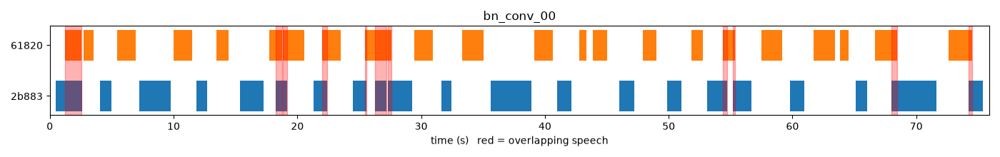

In [6]:
rows = [l.split() for l in open(f"{REPO}/data/diarization/rttm/bn_conv_00.rttm")]
segs = [(float(r[3]), float(r[3]) + float(r[4]), r[7], " ".join(r)) for r in rows]
pairs = [(a, b) for i, a in enumerate(segs) for b in segs[i + 1:] if a[2] != b[2] and a[0] < b[1] and b[0] < a[1]]
for a, b in pairs[:3]:
    print(a[3]); print(b[3]); print(f"   -> overlap {max(a[0], b[0]):.2f}-{min(a[1], b[1]):.2f} s\n")
display(Image(f"{REPO}/data/diarization/plots/bn_conv_00.png"))

## 2. Baseline: pyannote 3.1

Tuned on the even clips, reported on the odd clips (test half).

In [7]:
fresh("task1", "baseline", f"{EVAL} task1_diarization/diarize.py --run baseline")
sh(f"{EVAL} task1_diarization/evaluate.py --run baseline", tail=13)
print(open(f"{REPO}/results/task1/baseline/rttm/bn_conv_00.rttm").read()[:600])

bn_conv_08: 2 speakers, 2.6s
bn_conv_09: 2 speakers, 2.6s
=== baseline | collar=0.0 ===
      clip ref_spk hyp_spk  DER%  miss%  FA%  conf%
bn_conv_00       2       2 34.93  14.66 1.30  18.97
bn_conv_01       2       1 51.74   8.37 1.01  42.37
bn_conv_02       2       3 29.81   9.94 1.17  18.71
bn_conv_03       2       2  9.29   6.29 1.87   1.13
bn_conv_04       2       2 13.99  10.85 2.41   0.73
bn_conv_05       2       2 33.86   6.30 1.42  26.13
bn_conv_06       3       3 30.03   6.87 1.02  22.14
bn_conv_07       3       2 41.93   9.46 2.40  30.07
bn_conv_08       3       2 35.10   6.85 1.90  26.35
bn_conv_09       3       2 30.87   6.02 2.12  22.73
   OVERALL    None    None 31.31   8.57 1.66  21.09
SPEAKER bn_conv_00 1 0.605 0.354 <NA> <NA> SPEAKER_01 <NA> <NA>
SPEAKER bn_conv_00 1 0.959 1.316 <NA> <NA> SPEAKER_00 <NA> <NA>
SPEAKER bn_conv_00 1 1.111 1.401 <NA> <NA> SPEAKER_01 <NA> <NA>
SPEAKER bn_conv_00 1 2.748 0.742 <NA> <NA> SPEAKER_01 <NA> <NA>
SPEAKER bn_conv_00 1 4.064 0.844

**Error examples** (timelines: reference, prediction, error type)
- wrong speaker: bn_conv_00, 15.4–17.3 s
- two speakers merged: bn_conv_01
- backchannel in overlap given to the main speaker: bn_conv_09
- one speaker split into several: consult_B (step 7)

No short utterance was missed outright; short replies get the wrong speaker instead.


=== baseline: utterances by category (of 358) ===
category
ok               260
speaker_merge     48
wrong_speaker     39
speaker_split      6
overlap            4
missed             1

Short utterances (<1.6 s): 32% handled badly vs 22% of longer ones
Utterances touching overlap: 30% handled badly vs 26% without overlap

Worst example per category:
     category       clip speaker  start    end  error_frac   given_to                        text
wrong_speaker bn_conv_00   2b883 15.375 17.275        1.00      61820 শিল্পকেন্দ্র হিসেবে কাজ করে
speaker_merge bn_conv_01   c4973 56.103 57.103        1.00      7898e                    হলো সংসদ
      overlap bn_conv_01   c4973 49.439 50.039        1.00      7898e                         বধূ
speaker_split bn_conv_02   16877 41.599 43.799        1.00 SPEAKER_02              সরি বলতে থাকবে
       missed bn_conv_00   2b883 35.617 38.917        0.54        NaN    সে নিশ্চয়তা দেওয়া কঠিন


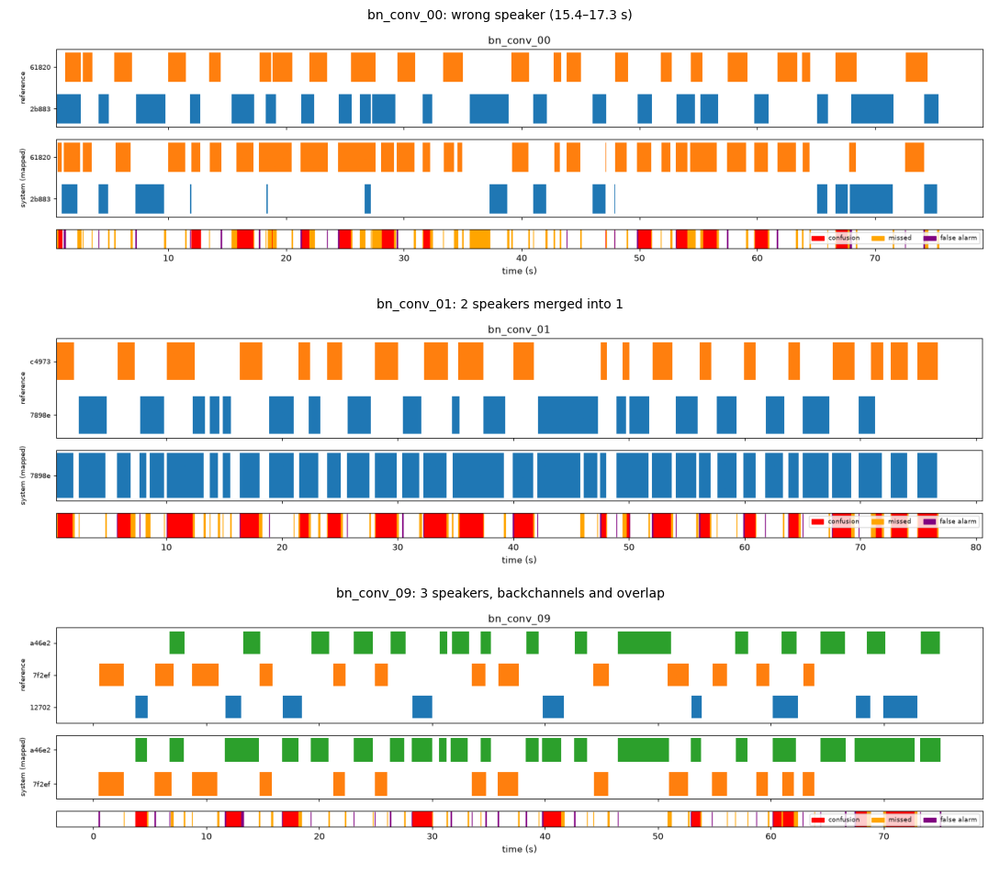

In [8]:
sh(f"{EVAL} task1_diarization/analyze_errors.py --run baseline", tail=40)
show_images([f"{REPO}/results/task1/baseline/plots/{c}.png" for c in ["bn_conv_00", "bn_conv_01", "bn_conv_09"]],
            ["bn_conv_00: wrong speaker (15.4–17.3 s)", "bn_conv_01: 2 speakers merged into 1", "bn_conv_09: 3 speakers, backchannels and overlap"])

## 3. Improvement: segment re-clustering

pyannote embeds 10 s windows that mix several short turns. `recluster.py` keeps the segments, embeds each whole
segment and clusters them again (threshold 0.70, chosen on the even clips).

bn_conv_08: 2 -> 3 speakers
bn_conv_09: 2 -> 4 speakers
=== rc_t0.70 | collar=0.0 ===
      clip ref_spk hyp_spk  DER%  miss%  FA%  conf%
bn_conv_00       2       2 20.90  14.66 1.30   4.94
bn_conv_01       2       1 51.74   8.37 1.01  42.37
bn_conv_02       2       4 31.28   9.94 1.17  20.17
bn_conv_03       2       2  8.24   6.29 1.87   0.07
bn_conv_04       2       2 13.87  10.85 2.41   0.61
bn_conv_05       2       2 12.85   6.30 1.42   5.13
bn_conv_06       3       3 10.81   7.10 1.02   2.68
bn_conv_07       3       3 20.64   9.46 2.40   8.78
bn_conv_08       3       3 11.12   6.85 1.90   2.37
bn_conv_09       3       4 14.10   6.02 2.12   5.96
   OVERALL    None    None 19.79   8.59 1.66   9.54
     run  dev_DER%  dev_conf% dev_spk_ok  test_DER%  test_conf% test_spk_ok  all_DER%  all_conf% all_spk_ok
baseline     23.01      18.83        3/5      28.08       25.80         2/5     25.55      22.33       5/10
rc_t0.70     10.63       6.41        4/5      15.93       13.66         3/

,dev_DER%,dev_conf%,dev_spk_ok,test_DER%,test_conf%,test_spk_ok,all_DER%,all_conf%,all_spk_ok
run,,,,,,,,,
baseline,23.01,18.83,3/5,28.08,25.80,2/5,25.55,22.33,5/10
rc_t0.70,10.63,6.41,4/5,15.93,13.66,3/5,13.29,10.04,7/10


       missed bn_conv_00   2b883 35.617 38.917        0.54      NaN সে নিশ্চয়তা দেওয়া কঠিন


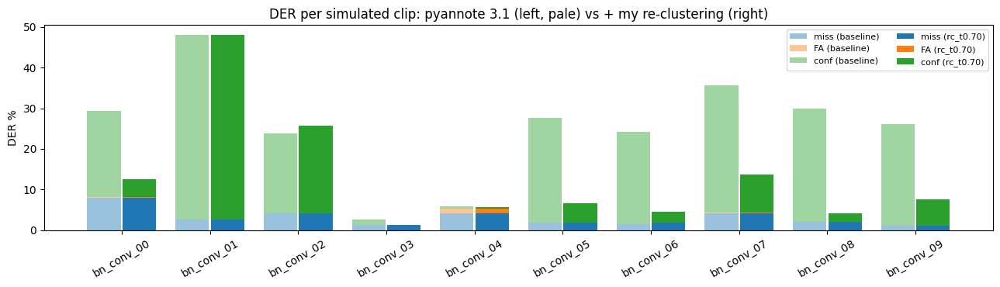

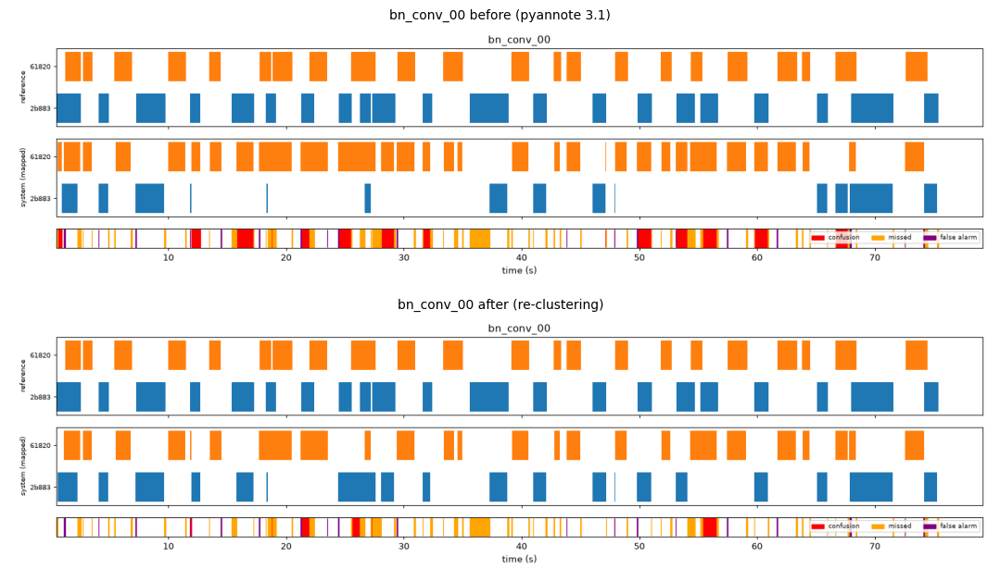

In [9]:
fresh("task1", "rc_t0.70", f"{EVAL} task1_diarization/recluster.py --src baseline --run rc_t0.70 --threshold 0.70")
sh(f"{EVAL} task1_diarization/evaluate.py --run rc_t0.70", tail=13)
sh(f"{EVAL} task1_diarization/compare.py baseline rc_t0.70")
sub = pd.read_csv(f"{SUB}/task1/comparison_collar0.25.csv").set_index("run")
new = pd.read_csv(f"{NEW}/task1/comparison_collar0.25.csv").set_index("run")
for run in ["baseline", "rc_t0.70"]:
    check(f"simulated test half DER, {run}", sub.loc[run, "test_DER%"], new.loc[run, "test_DER%"])
display(new)

# before / after per clip, split into missed speech, false alarm and speaker confusion
sh(f"{EVAL} task1_diarization/analyze_errors.py --run rc_t0.70", tail=1)
per = {run: pd.read_csv(f"{NEW}/task1/{run}/der_collar0.25.csv").query("clip != 'OVERALL'").set_index("clip") for run in ["baseline", "rc_t0.70"]}
fig, ax = plt.subplots(figsize=(13, 3.8))
x = range(len(per["baseline"]))
for j, (run, df) in enumerate(per.items()):
    bottom = 0
    for k, col in enumerate(["miss%", "FA%", "conf%"]):
        ax.bar([i + 0.4 * j for i in x], df[col], 0.38, bottom=bottom, color=f"C{k}", alpha=1 if j else 0.45,
               label=f"{col[:-1]} ({run})")
        bottom = bottom + df[col]
ax.set_xticks([i + 0.2 for i in x]); ax.set_xticklabels(per["baseline"].index, rotation=30)
ax.set_ylabel("DER %"); ax.set_title("DER per simulated clip: pyannote 3.1 (left, pale) vs + my re-clustering (right)")
ax.legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()
show_images([f"{REPO}/results/task1/{r}/plots/bn_conv_00.png" for r in ["baseline", "rc_t0.70"]],
            ["bn_conv_00 before (pyannote 3.1)", "bn_conv_00 after (re-clustering)"])

## 4. Indic DiarBench Bengali

12.6 h of real Bengali (meetings, far-field, in-the-wild), 2–8 speakers, human labels. Split by recording:
dev 3.3 h for all decisions, test 9.3 h scored once. Overlap regions are written as their own RTTM.

Generating test split: 100%|██████████| 104/104 [00:14<00:00,  7.17 examples/s]
                   clips  recordings  hours  spk_mean  overlap_pct
split condition                                                   
dev   Far field        9           9    0.8       2.1          4.0
      In the wild     11          11    0.9       3.4          4.6
      Near field      28           9    1.6       5.1         16.6
test  Far field       14          14    3.3       2.9          6.5
      In the wild     17          17    3.2       4.2          4.0
      Near field      25          14    2.8       3.0          6.0
label issues: {'dropped: end <= start': 1, 'clipped: past audio end': 22, 'empty transcript (kept)': 1}
split identical: True | 208 / 208 reference + overlap RTTMs identical
SPEAKER bengali_097 1 14.025 1.006 <NA> <NA> overlap <NA> <NA>
SPEAKER bengali_097 1 16.102 0.376 <NA> <NA> overlap <NA> <NA>
SPEAKER bengali_097 1 17.574 0.880 <NA> <NA> overlap <NA> <NA>
SPEAKER bengali_097 1

clips  recordings  hours speakers  overlap_pct
split condition                                                  
dev   Far field        9           9    0.8      2–3          4.0
      In the wild     11          11    0.9      2–6          4.6
      Near field      28           9    1.6      2–8         16.6
test  Far field       14          14    3.3      2–8          6.5
      In the wild     17          17    3.2      2–8          4.0
      Near field      25          14    2.8      2–5          6.0

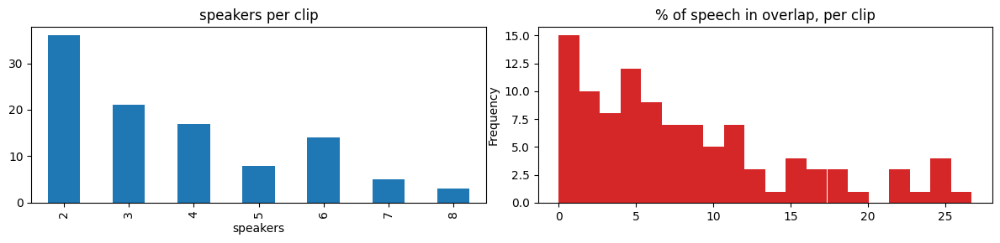

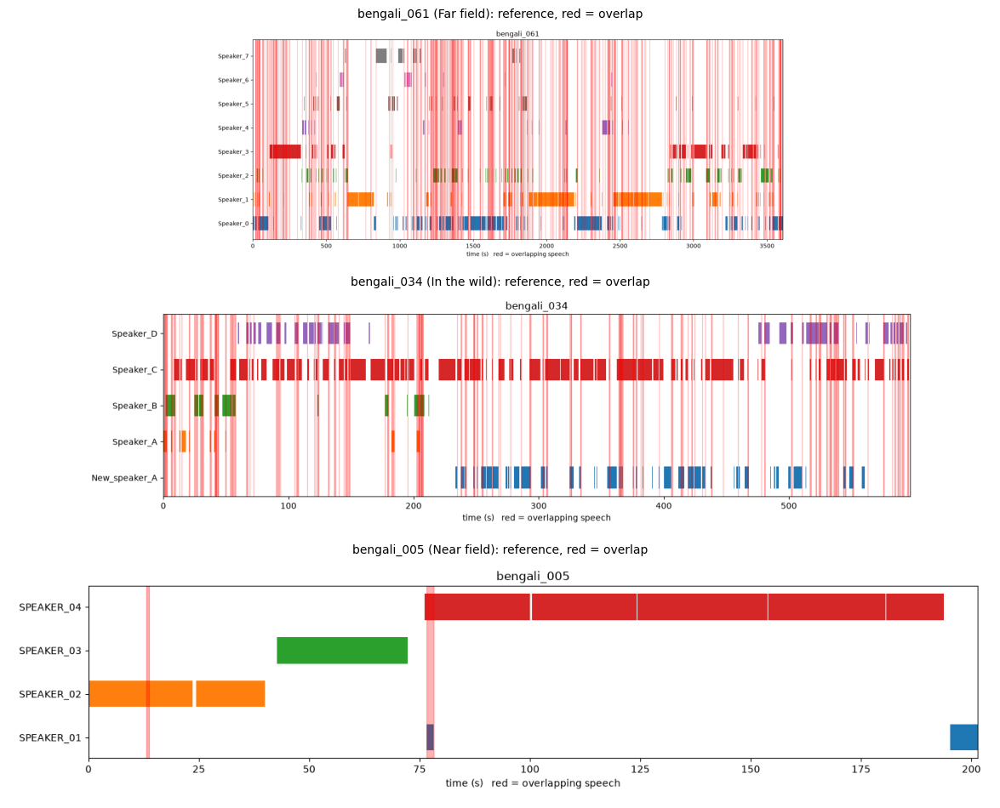

In [10]:
shutil.copytree(f"{REPO}/data/diarbench", "/content/submitted_data/diarbench", dirs_exist_ok=True)
sh(f"{EVAL} data/prepare_diarbench.py --dev_fraction 0.4", tail=14)
same_split = filecmp.cmp("/content/submitted_data/diarbench/split.csv", f"{REPO}/data/diarbench/split.csv", shallow=False)
n = diff = 0
for split in ["dev", "test"]:
    for kind in ["rttm", "overlap"]:
        for p in Path(f"/content/submitted_data/diarbench/{split}/{kind}").glob("*.rttm"):
            n += 1
            diff += not filecmp.cmp(p, f"{REPO}/data/diarbench/{split}/{kind}/{p.name}", shallow=False)
print("split identical:", same_split, f"| {n - diff} / {n} reference + overlap RTTMs identical")
print(open(f"{REPO}/data/diarbench/test/overlap/bengali_097.rttm").read()[:400])

summ = pd.read_csv(f"{REPO}/data/diarbench/summary.csv")
display(summ.groupby(["split", "condition"]).agg(clips=("clip", "count"), recordings=("recording", "nunique"),
        hours=("duration_s", lambda s: round(s.sum() / 3600, 2)), speakers=("speakers", lambda s: f"{s.min()}–{s.max()}"),
        overlap_pct=("overlap_pct", "mean")).round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
summ.speakers.value_counts().sort_index().plot.bar(ax=ax[0], title="speakers per clip", color="C0")
summ.overlap_pct.plot.hist(ax=ax[1], bins=20, title="% of speech in overlap, per clip", color="C3")
plt.tight_layout(); plt.show()
ex = summ[summ.split == "test"].groupby("condition").clip.first()
show_images([f"{REPO}/data/diarbench/test/plots/{c}.png" for c in ex], [f"{c} ({k}): reference, red = overlap" for k, c in ex.items()])

## 5. Dev experiments

DER is also split into inside / outside overlap.

| System | Idea |
|---|---|
| pyannote 3.1 | baseline |
| + re-clustering | step 3 |
| community-1 | newer pyannote pipeline (VBx clustering) |
| PixIT | diarization + separation, can hear a second voice |
| overlap fusion (mine) | community-1 + speakers PixIT hears in overlap |

In [11]:
W, DB = f"{DATA}/diarbench", "data/diarbench"
def evaluate(run, split, ref=None, ov=None):
    ref, ov = ref or f"{DB}/{split}/rttm", ov or f"{DB}/{split}/overlap"
    sh(f"{EVAL} task1_diarization/evaluate.py --run {run} --ref_dir {ref} --overlap_dir {ov}", tail=1)

def overall(root, run):
    df = pd.read_csv(f"{root}/task1/{run}/der_collar0.25.csv")
    return df[df["clip"] == "OVERALL"].iloc[0]

fresh("task1", "db_dev_baseline", f"{EVAL} task1_diarization/diarize.py --run db_dev_baseline --wav_dir {W}/dev --ref_dir {DB}/dev/rttm")
evaluate("db_dev_baseline", "dev")
fresh("task1", "db_dev_rc0.7", f"{EVAL} task1_diarization/recluster.py --src db_dev_baseline --run db_dev_rc0.7 --threshold 0.7 "
                               f"--wav_dir {W}/dev --ref_dir {DB}/dev/rttm")
evaluate("db_dev_rc0.7", "dev")
fresh("task1", "db_dev_community1", f"{P4} task1_diarization/diarize_overlap_aware.py --system community1 --run db_dev_community1 --wav_dir {W}/dev")
evaluate("db_dev_community1", "dev")
for run in ["db_dev_baseline", "db_dev_rc0.7", "db_dev_community1"]:
    s, n = overall(SUB, run), overall(NEW, run)
    check(f"DiarBench dev DER, {run}", round(s["DER%"], 1), round(n["DER%"], 1))
    check(f"DiarBench dev DER inside overlap, {run}", round(s["DER_overlap%"], 1), round(n["DER_overlap%"], 1))

bengali_103: 2 speakers, 3.0s
bengali_104: 2 speakers, 2.9s
        41.61      16.35     OVERALL    None    None 22.44  11.39  2.12   8.93
bengali_103: 2 -> 6 speakers
bengali_104: 2 -> 1 speakers
        47.85      21.92     OVERALL    None    None 28.34  11.54  2.09  14.71
bengali_103: 2 speakers, 2.98s
bengali_104: 2 speakers, 2.93s
        39.83      14.92     OVERALL    None    None 20.82  11.39  2.12   7.31
✓  DiarBench dev DER, db_dev_baseline: submitted 18.3 | reproduced 18.3
✓  DiarBench dev DER inside overlap, db_dev_baseline: submitted 38.6 | reproduced 38.6
✓  DiarBench dev DER, db_dev_rc0.7: submitted 24.4 | reproduced 24.4
✓  DiarBench dev DER inside overlap, db_dev_rc0.7: submitted 45.4 | reproduced 45.4
✓  DiarBench dev DER, db_dev_community1: submitted 16.7 | reproduced 16.7
✓  DiarBench dev DER inside overlap, db_dev_community1: submitted 36.5 | reproduced 36.5


PixIT runs in 5 min windows (RAM limit) and finished on 32 dev clips, so these systems are compared on those 32.
With `RUN_PIXIT = False` the submitted PixIT output is used; the fusion and scoring are re-run.

RUN_PIXIT = False: using the submitted PixIT RTTMs (the fusion and all scores below are still recomputed)
48 clips, 2176.2 s of overlapped speech added
48 clips, 720.4 s of overlapped speech added
        43.24      13.63     OVERALL    None    None 21.90  12.73 1.20   7.97
✓  dev-32 DER, db_dev_baseline: submitted 17.8 | reproduced 17.8
✓  dev-32 DER inside overlap, db_dev_baseline: submitted 40.2 | reproduced 40.2
        41.32      13.29     OVERALL    None    None 20.99  12.73 1.20   7.05
✓  dev-32 DER, db_dev_community1: submitted 16.9 | reproduced 16.9
✓  dev-32 DER inside overlap, db_dev_community1: submitted 38.0 | reproduced 38.0
        41.89      46.56     OVERALL    None    None  46.11   5.02 20.18  20.92
✓  dev-32 DER, db_dev_pixit: submitted 42.0 | reproduced 42.0
✓  dev-32 DER inside overlap, db_dev_pixit: submitted 39.4 | reproduced 39.4
        38.55      32.99     OVERALL    None    None 34.61   7.34 19.98   7.29
✓  dev-32 DER, db_dev_community1_fusion: submitted 30.8

,system (32 dev clips),DER,miss,FA,conf,DER in overlap,DER elsewhere
0,db_dev_baseline,17.8,10.2,0.5,7.2,40.2,11.2
1,db_dev_community1,16.9,10.2,0.5,6.3,38.0,11.0
2,db_dev_pixit,42.0,3.7,18.4,20.0,39.4,41.9
3,db_dev_community1_fusion,30.8,6.2,18.3,6.3,37.7,28.8
4,db_dev_fuse_mo0.0_adj0.0,17.6,7.5,3.7,6.5,33.7,13.1


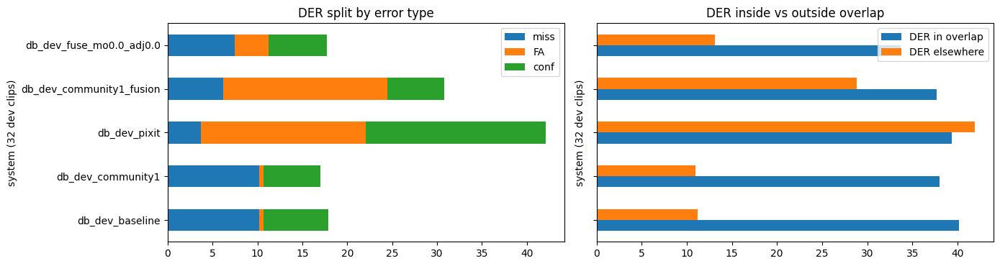

In [12]:
clips32 = sorted(p.stem for p in Path(f"{SUB}/task1/db_dev_pixit/rttm").glob("*.rttm"))
S32 = "/content/dev32"
for kind in ["rttm", "overlap", "wav"]:
    os.makedirs(f"{S32}/{kind}", exist_ok=True)
for c in clips32:
    shutil.copy(f"{REPO}/{DB}/dev/rttm/{c}.rttm", f"{S32}/rttm/")
    shutil.copy(f"{REPO}/{DB}/dev/overlap/{c}.rttm", f"{S32}/overlap/")
    if not os.path.exists(f"{S32}/wav/{c}.wav"):
        os.symlink(f"{W}/dev/{c}.wav", f"{S32}/wav/{c}.wav")
if RUN_PIXIT:
    fresh("task1", "db_dev_pixit", f"{EVAL} task1_diarization/diarize_overlap_aware.py --system pixit --run db_dev_pixit --wav_dir {S32}/wav --chunk_s 300")
else:
    print("RUN_PIXIT = False: using the submitted PixIT RTTMs (the fusion and all scores below are still recomputed)")
sh(f"{EVAL} task1_diarization/overlap_fusion.py --base db_dev_community1 --pixit db_dev_pixit --run db_dev_community1_fusion", tail=1)
sh(f"{EVAL} task1_diarization/overlap_fusion.py --base db_dev_community1 --pixit db_dev_pixit --run db_dev_fuse_mo0.0_adj0.0 --adjacent_s 0.0", tail=1)

expected = {"db_dev_baseline": (17.8, 40.2), "db_dev_community1": (16.9, 38.0), "db_dev_pixit": (42.0, 39.4),   # notes.md
            "db_dev_community1_fusion": (30.8, 37.7), "db_dev_fuse_mo0.0_adj0.0": (17.6, 33.7)}
rows = []
for run, (der, der_ov) in expected.items():
    sub_run = f"{run}_on32"
    shutil.copytree(f"{NEW}/task1/{run}/rttm", f"{NEW}/task1/{sub_run}/rttm", dirs_exist_ok=True)
    evaluate(sub_run, "dev", ref=f"{S32}/rttm", ov=f"{S32}/overlap")
    o = overall(NEW, sub_run)
    rows.append({"system (32 dev clips)": run, "DER": o["DER%"], "miss": o["miss%"], "FA": o["FA%"], "conf": o["conf%"],
                 "DER in overlap": o["DER_overlap%"], "DER elsewhere": o["DER_rest%"]})
    check(f"dev-32 DER, {run}", der, round(o["DER%"], 1))
    check(f"dev-32 DER inside overlap, {run}", der_ov, round(o["DER_overlap%"], 1))
dev = pd.DataFrame(rows).round(1)
display(dev)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
dev.set_index("system (32 dev clips)")[["miss", "FA", "conf"]].plot.barh(stacked=True, ax=ax[0], title="DER split by error type")
dev.set_index("system (32 dev clips)")[["DER in overlap", "DER elsewhere"]].plot.barh(ax=ax[1], title="DER inside vs outside overlap")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

**Decision:** re-clustering hurts on real meetings. PixIT finds the second voice but adds false alarms. Fusion lowers
DER inside overlap (38.0 → 33.7) but not overall. community-1 is best overall, so it is used.

## 6. Test (9.3 h): pyannote 3.1 vs community-1

bengali_099: 2 speakers, 3.0s
bengali_100: 2 speakers, 2.6s
bengali_099: 2 speakers, 3.13s
bengali_100: 2 speakers, 2.64s
        41.42      20.53     OVERALL    None    None 23.03   7.96  4.04  11.03
✓  DiarBench TEST DER, db_test_baseline: submitted 19.8 | reproduced 19.8
✓  DiarBench TEST DER inside overlap, db_test_baseline: submitted 38.2 | reproduced 38.2
✓  DiarBench TEST speakers counted right, db_test_baseline: submitted 35 | reproduced 35
        38.27      17.47     OVERALL    None    None 19.93   7.96  4.04   7.93
✓  DiarBench TEST DER, db_test_community1: submitted 16.7 | reproduced 16.7
✓  DiarBench TEST DER inside overlap, db_test_community1: submitted 35.0 | reproduced 35.0
✓  DiarBench TEST speakers counted right, db_test_community1: submitted 46 | reproduced 46


,system,DER,miss,FA,conf,DER in overlap,DER elsewhere,speakers right,DER Far field,DER In the wild,DER Near field
0,db_test_baseline,19.8,6.4,3.1,10.3,38.2,18.0,35/56,33.3,8.4,17.2
1,db_test_community1,16.7,6.4,3.1,7.3,35.0,15.0,46/56,24.5,8.8,17.0


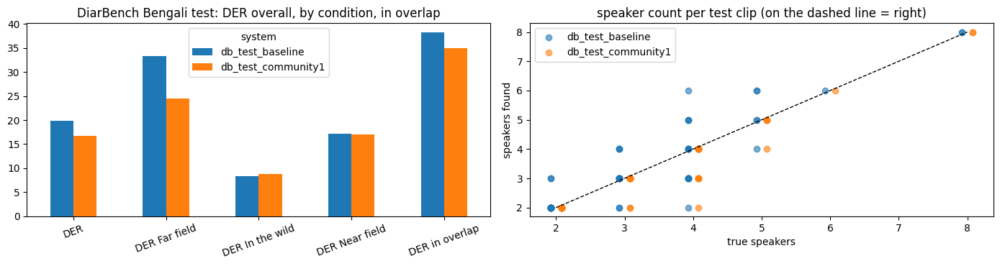

In [13]:
fresh("task1", "db_test_baseline", f"{EVAL} task1_diarization/diarize.py --run db_test_baseline --wav_dir {W}/test --ref_dir {DB}/test/rttm")
fresh("task1", "db_test_community1", f"{P4} task1_diarization/diarize_overlap_aware.py --system community1 --run db_test_community1 --wav_dir {W}/test")
cond = pd.read_csv(f"{REPO}/{DB}/summary.csv").set_index("clip")["condition"]
rows = []
for run in ["db_test_baseline", "db_test_community1"]:
    evaluate(run, "test")
    df = pd.read_csv(f"{NEW}/task1/{run}/der_collar0.25.csv")
    o, per = df[df["clip"] == "OVERALL"].iloc[0], df[df["clip"] != "OVERALL"]
    g = per.assign(condition=per["clip"].map(cond)).groupby("condition")[["miss_s", "fa_s", "conf_s", "speech_s"]].sum()
    by_cond = (100 * (g.miss_s + g.fa_s + g.conf_s) / g.speech_s).round(1)
    spk_right = int((per.ref_spk == per.hyp_spk).sum())
    rows.append({"system": run, "DER": o["DER%"], "miss": o["miss%"], "FA": o["FA%"], "conf": o["conf%"],
                 "DER in overlap": o["DER_overlap%"], "DER elsewhere": o["DER_rest%"],
                 "speakers right": f"{spk_right}/{len(per)}", **{f"DER {k}": v for k, v in by_cond.items()}})
    s = overall(SUB, run)
    check(f"DiarBench TEST DER, {run}", round(s["DER%"], 1), round(o["DER%"], 1))
    check(f"DiarBench TEST DER inside overlap, {run}", round(s["DER_overlap%"], 1), round(o["DER_overlap%"], 1))
    sp = pd.read_csv(f"{SUB}/task1/{run}/der_collar0.25.csv"); sp = sp[sp["clip"] != "OVERALL"]
    check(f"DiarBench TEST speakers counted right, {run}", int((sp.ref_spk == sp.hyp_spk).sum()), spk_right, tol=0)
test = pd.DataFrame(rows).round(1)
display(test)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
cols = ["DER"] + [c for c in test.columns if c.startswith("DER ") and c not in ("DER in overlap", "DER elsewhere")] + ["DER in overlap"]
test.set_index("system")[cols].T.plot.bar(ax=ax[0], rot=20, title="DiarBench Bengali test: DER overall, by condition, in overlap")
for j, run in enumerate(["db_test_baseline", "db_test_community1"]):
    per = pd.read_csv(f"{NEW}/task1/{run}/der_collar0.25.csv").query("clip != 'OVERALL'")
    ax[1].scatter(per.ref_spk + (j - 0.5) * 0.15, per.hyp_spk, alpha=0.6, label=run)
ax[1].plot([2, 8], [2, 8], "k--", lw=1); ax[1].set_xlabel("true speakers"); ax[1].set_ylabel("speakers found")
ax[1].set_title("speaker count per test clip (on the dashed line = right)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Samples

`data/samples/diarization/`: 9 recordings, each with audio, reference RTTM, overlap RTTM, predicted RTTMs
before / after, and a timeline.

               sample               system  ref_speakers  found_speakers  DER%  miss%  FA%  conf%  DER_in_overlap%
diarbench_bengali_012           pyannote31             4               5 17.29   9.18 0.40   7.71             39.4
diarbench_bengali_012           community1             4               4 13.98   9.18 0.40   4.39             38.1
diarbench_bengali_097           pyannote31             2               2  7.07   2.08 2.19   2.80              7.0
diarbench_bengali_097           community1             2               2  4.73   2.08 2.19   0.46              7.0
diarbench_bengali_072           pyannote31             2               2 42.28   5.85 4.62  31.80             54.3
diarbench_bengali_072           community1             2               2 24.46   5.85 4.62  13.98             54.3
diarbench_bengali_013           pyannote31             4               3 14.30  10.08 0.79   3.44             29.9
diarbench_bengali_013           community1             4               3 15.94  

# Diarization samples: audio + reference + predicted speaker annotations

Each folder: `audio.wav`, `reference.rttm`, `reference_overlap.rttm`, `predicted_<system>.rttm` (before and after the improvement, the saved outputs of the reported runs) and `timeline.png`. Built by `data/make_diarization_samples.py`; DER with pyannote.metrics, collar 0.25 s. RTTM: `SPEAKER <file> 1 <start> <duration> <NA> <NA> <speaker> <NA> <NA>`; overlapping speech = two lines covering the same time.

| sample | source | dur (s) | ref spk | overlap % | system | spk found | DER % | miss | FA | conf | DER in overlap | what to look at |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| `diarbench_bengali_012` | DiarBench test (near-field, 4 speakers) | 195.9 | 4 | 10.7 | pyannote31 | 5 | **17.29** | 9.18 | 0.4 | 7.71 | 39.4 | one speaker identified as multiple speakers: 3.1 finds 5 speakers for 4; community-1 finds 4 |
| `diarbench_bengali_012` | DiarBench test (near-field, 4 speakers) | 195.9 | 4 | 10.7 | community1 | 4 | **13.98** | 9.18 | 0.4 | 4.39 | 38.1 | one speaker identified as multiple speakers: 3.1 finds 5 speakers for 4; community-1 finds 4 |
| `diarbench_bengali_097` | DiarBench test (near-field, 2 speakers, 13 % overlap) | 64.0 | 2 | 15.8 | pyannote31 | 2 | **7.07** | 2.08 | 2.19 | 2.8 | 7.0 | overlapping speech (13 %): DER inside overlap 7 % for both; community-1 removes most confusion (2.8 -> 0.5) |
| `diarbench_bengali_097` | DiarBench test (near-field, 2 speakers, 13 % overlap) | 64.0 | 2 | 15.8 | community1 | 2 | **4.73** | 2.08 | 2.19 | 0.46 | 7.0 | overlapping speech (13 %): DER inside overlap 7 % for both; community-1 removes most confusion (2.8 -> 0.5) |
| `diarbench_bengali_072` | DiarBench test (far-field, 2 speakers) | 318.4 | 2 | 3.1 | pyannote31 | 2 | **42.28** | 5.85 | 4.62 | 31.8 | 54.3 | incorrect speaker assignment in far-field audio: confusion 31.8 -> 14.0; overlap stays the hardest part (54 %) |
| `diarbench_bengali_072` | DiarBench test (far-field, 2 speakers) | 318.4 | 2 | 3.1 | community1 | 2 | **24.46** | 5.85 | 4.62 | 13.98 | 54.3 | incorrect speaker assignment in far-field audio: confusion 31.8 -> 14.0; overlap stays the hardest part (54 %) |
| `diarbench_bengali_013` | DiarBench test (near-field, 4 speakers, 12 % overlap) | 204.9 | 4 | 13.3 | pyannote31 | 3 | **14.3** | 10.08 | 0.79 | 3.44 | 29.9 | a clip where the improvement does NOT help (kept on purpose): both systems find 3 of 4 speakers |
| `diarbench_bengali_013` | DiarBench test (near-field, 4 speakers, 12 % overlap) | 204.9 | 4 | 13.3 | community1 | 3 | **15.94** | 10.08 | 0.79 | 5.07 | 32.9 | a clip where the improvement does NOT help (kept on purpose): both systems find 3 of 4 speakers |
| `sim_bn_conv_00` | simulated conversation (OpenSLR speakers, 2 speakers) | 75.9 | 2 | 10.8 | pyannote31 | 2 | **29.41** | 8.07 | 0.03 | 21.3 | 18.8 | incorrect speaker assignment (15.4-17.3 s given to the other speaker); fixed by my segment re-clustering |
| `sim_bn_conv_00` | simulated conversation (OpenSLR speakers, 2 speakers) | 75.9 | 2 | 10.8 | pyannote31_recluster | 2 | **12.5** | 8.07 | 0.03 | 4.39 | 18.8 | incorrect speaker assignment (15.4-17.3 s given to the other speaker); fixed by my segment re-clustering |
| `sim_bn_conv_09` | simulated conversation (OpenSLR speakers, 3 speakers, 15 dB noise) | 75.5 | 3 | 6.1 | pyannote31 | 2 | **26.03** | 1.19 | 0.0 | 24.84 | 17.2 | speaker merge (3 -> 2) by 3.1; re-clustering separates them but over-splits (4) |
| `sim_bn_conv_09` | simulated conversation (OpenSLR speakers, 3 speakers, 15 dB noise) | 75.5 | 3 | 6.1 | pyannote31_recluster | 4 | **7.6** | 1.19 | 0.0 | 6.41 | 17.2 | speaker merge (3 -> 2) by 3.1; re-clustering separates them but over-splits (4) |
| `real_consult_A` | my real role-play consultation (doctor + patient) | 76.4 | 2 | 0.4 | pyannote31 | 2 | **1.61** | 1.49 | 0.11 | 0.0 | 0.0 | clean 2-speaker recording: both systems near-perfect (DER 1.6) |
| `real_consult_A` | my real role-play consultation (doctor + patient) | 76.4 | 2 | 0.4 | community1 | 2 | **1.61** | 1.49 | 0.11 | 0.0 | 0.0 | clean 2-speaker recording: both systems near-perfect (DER 1.6) |
| `real_consult_B` | my real role-play consultation (attendant + doctor, attendant speaks first) | 56.7 | 2 | 0.0 | pyannote31 | 3 | **15.23** | 4.07 | 0.0 | 11.16 |  | one speaker identified as multiple: 3.1 gives the attendant's short replies a third label; community-1 finds 2 |
| `real_consult_B` | my real role-play consultation (attendant + doctor, attendant speaks first) | 56.7 | 2 | 0.0 | community1 | 2 | **4.07** | 4.07 | 0.0 | 0.0 |  | one speaker identified as multiple: 3.1 gives the attendant's short replies a third label; community-1 finds 2 |
| `synthetic_S05` | synthetic consultation (Parler-TTS, doctor interrupts patient) | 37.8 | 2 | 8.0 | pyannote31 | 2 | **6.69** | 6.69 | 0.0 | 0.0 | 13.6 | annotated overlap (doctor interrupts at 5.27 s, patient speaks until 5.77 s); all errors are missed speech, mostly the overlapped second voice |
| `synthetic_S05` | synthetic consultation (Parler-TTS, doctor interrupts patient) | 37.8 | 2 | 8.0 | community1 | 2 | **6.69** | 6.69 | 0.0 | 0.0 | 13.6 | annotated overlap (doctor interrupts at 5.27 s, patient speaks until 5.77 s); all errors are missed speech, mostly the overlapped second voice |

Systems: `pyannote31` = pyannote/speaker-diarization-3.1 (baseline); `community1` = pyannote/speaker-diarization-community-1 (the Task 1 improvement chosen on DiarBench dev, used in the final pipeline); `pyannote31_recluster` = 3.1 + my segment-level re-clustering (the improvement on simulated conversations). DiarBench audio: sarvamai/indic-diarbench (CC BY 4.0).


### diarbench_bengali_012: DiarBench test (near-field, 4 speakers)
one speaker identified as multiple speakers: 3.1 finds 5 speakers for 4; community-1 finds 4

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,5,17.29,9.18,0.4,7.71,39.4
1,community1,4,13.98,9.18,0.4,4.39,38.1


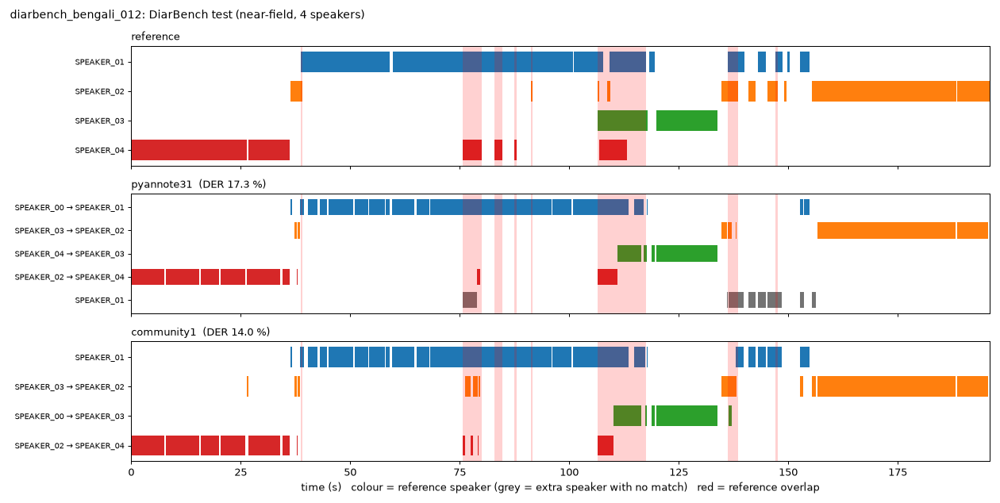

### diarbench_bengali_097: DiarBench test (near-field, 2 speakers, 13 % overlap)
overlapping speech (13 %): DER inside overlap 7 % for both; community-1 removes most confusion (2.8 -> 0.5)

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,2,7.07,2.08,2.19,2.80,7.0
1,community1,2,4.73,2.08,2.19,0.46,7.0


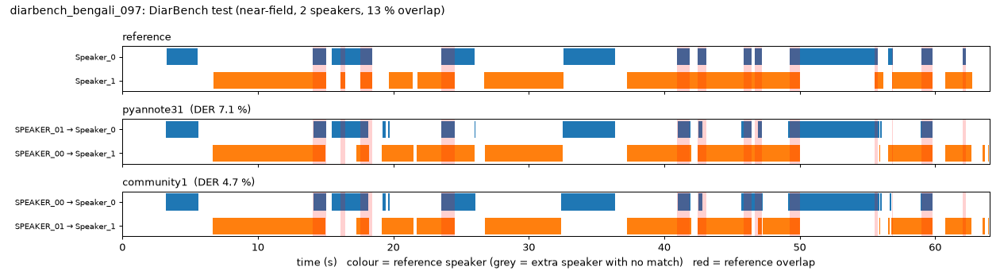

### diarbench_bengali_072: DiarBench test (far-field, 2 speakers)
incorrect speaker assignment in far-field audio: confusion 31.8 -> 14.0; overlap stays the hardest part (54 %)

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,2,42.28,5.85,4.62,31.80,54.3
1,community1,2,24.46,5.85,4.62,13.98,54.3


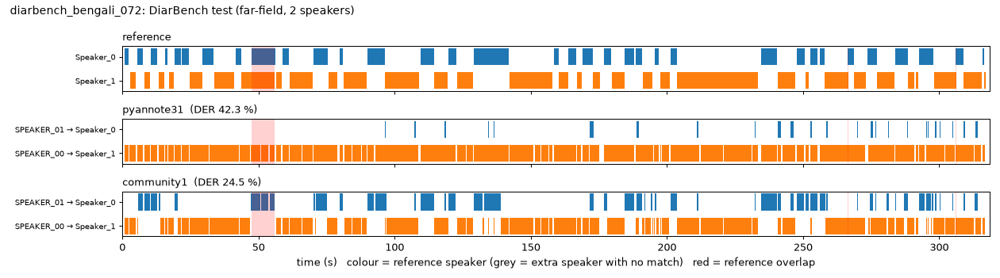

### diarbench_bengali_013: DiarBench test (near-field, 4 speakers, 12 % overlap)
a clip where the improvement does NOT help (kept on purpose): both systems find 3 of 4 speakers

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,3,14.30,10.08,0.79,3.44,29.9
1,community1,3,15.94,10.08,0.79,5.07,32.9


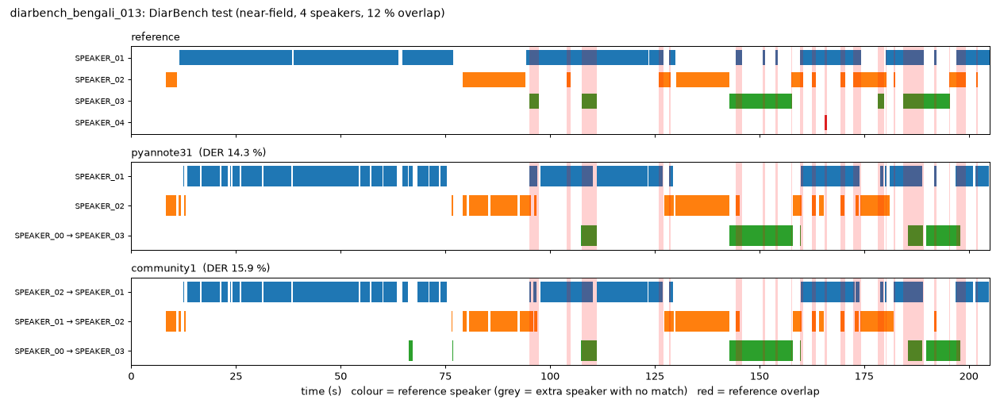

### sim_bn_conv_00: simulated conversation (OpenSLR speakers, 2 speakers)
incorrect speaker assignment (15.4-17.3 s given to the other speaker); fixed by my segment re-clustering

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,2,29.41,8.07,0.03,21.30,18.8
1,pyannote31_recluster,2,12.50,8.07,0.03,4.39,18.8


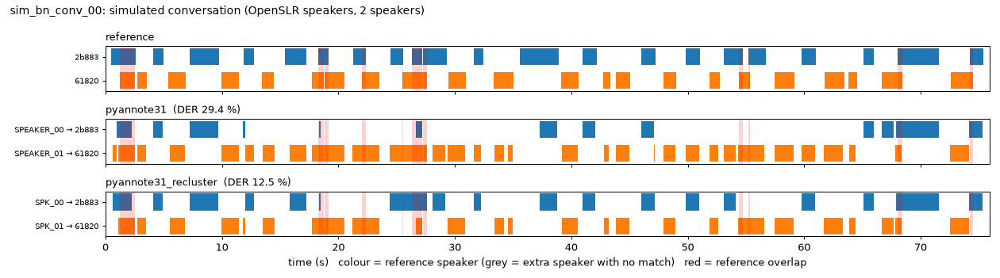

### sim_bn_conv_09: simulated conversation (OpenSLR speakers, 3 speakers, 15 dB noise)
speaker merge (3 -> 2) by 3.1; re-clustering separates them but over-splits (4)

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,2,26.03,1.19,0.0,24.84,17.2
1,pyannote31_recluster,4,7.60,1.19,0.0,6.41,17.2


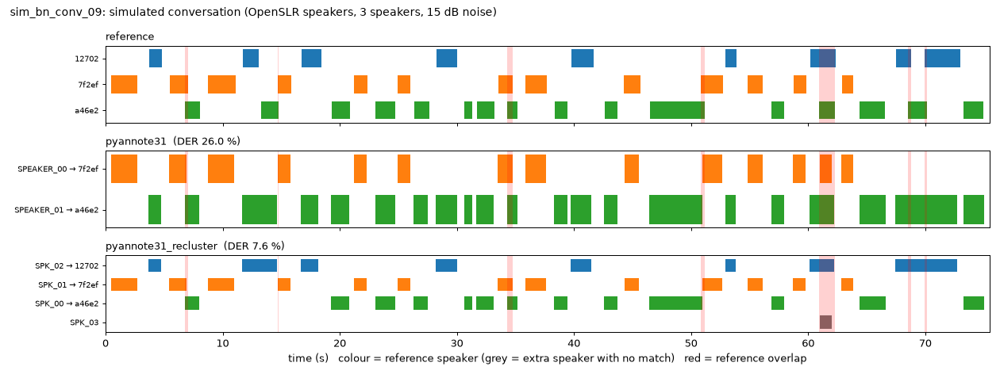

### real_consult_A: my real role-play consultation (doctor + patient)
clean 2-speaker recording: both systems near-perfect (DER 1.6)

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,2,1.61,1.49,0.11,0.0,0.0
1,community1,2,1.61,1.49,0.11,0.0,0.0


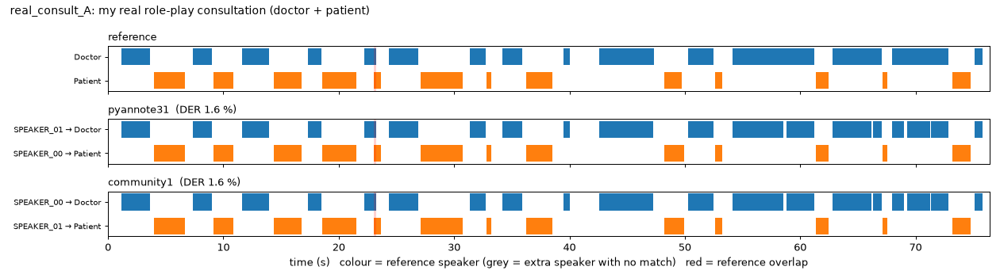

### real_consult_B: my real role-play consultation (attendant + doctor, attendant speaks first)
one speaker identified as multiple: 3.1 gives the attendant's short replies a third label; community-1 finds 2

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,3,15.23,4.07,0.0,11.16,NaN
1,community1,2,4.07,4.07,0.0,0.00,NaN


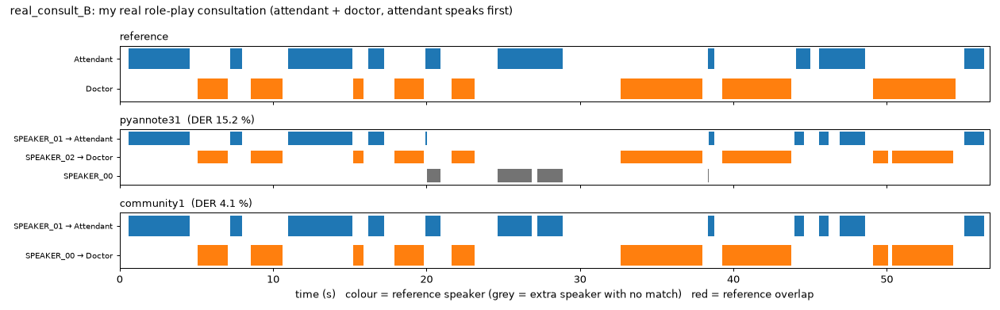

### synthetic_S05: synthetic consultation (Parler-TTS, doctor interrupts patient)
annotated overlap (doctor interrupts at 5.27 s, patient speaks until 5.77 s); all errors are missed speech, mostly the overlapped second voice

,system,found_speakers,DER%,miss%,FA%,conf%,DER_in_overlap%
0,pyannote31,2,6.69,6.69,0.0,0.0,13.6
1,community1,2,6.69,6.69,0.0,0.0,13.6


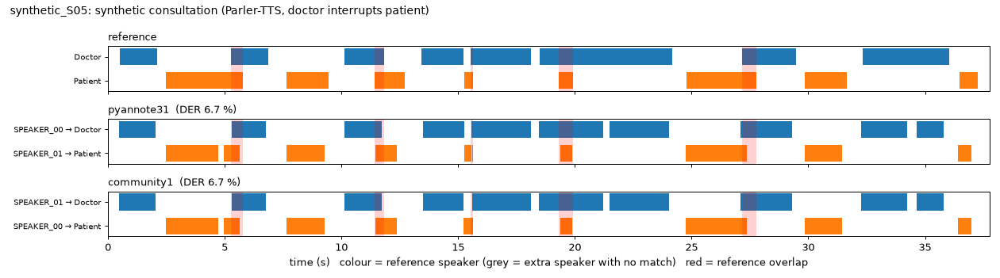

In [14]:
os.makedirs(f"{DATA}/tts_consultation", exist_ok=True)
for f in Path(f"{REPO}/data/tts_consultation/audio").glob("*.wav"):
    shutil.copy(f, f"{DATA}/tts_consultation/")
sh(f"{EVAL} data/make_diarization_samples.py", tail=20)
display(Markdown(open(f"{REPO}/data/samples/diarization/README.md", encoding="utf-8").read()))
samples = pd.read_csv(f"{REPO}/data/samples/diarization/samples.csv")
for s, g in samples.groupby("sample", sort=False):
    display(Markdown(f"### {s}: {g.set.iloc[0]}\n{g.what_to_look_at.iloc[0]}"))
    display(g[["system", "found_speakers", "DER%", "miss%", "FA%", "conf%", "DER_in_overlap%"]].reset_index(drop=True))
    display(Audio(f"{REPO}/data/samples/diarization/{s}/audio.wav"))
    display(Image(f"{REPO}/data/samples/diarization/{s}/timeline.png"))

## Summary

All checks in one table. ✗ = outside the tolerance.

In [15]:
summary = pd.DataFrame(CHECKS)
print(f"{(summary.match == '✓').sum()} / {len(summary)} results reproduced within tolerance")
summary

24 / 24 results reproduced within tolerance


,result,submitted,reproduced,tolerance,match
0,"simulated test half DER, baseline",28.08,28.08,0.15,✓
1,"simulated test half DER, rc_t0.70",15.93,15.93,0.15,✓
2,"DiarBench dev DER, db_dev_baseline",18.30,18.30,0.15,✓
3,"DiarBench dev DER inside overlap, db_dev_baseline",38.60,38.60,0.15,✓
4,"DiarBench dev DER, db_dev_rc0.7",24.40,24.40,0.15,✓
5,"DiarBench dev DER inside overlap, db_dev_rc0.7",45.40,45.40,0.15,✓
6,"DiarBench dev DER, db_dev_community1",16.70,16.70,0.15,✓
7,"DiarBench dev DER inside overlap, db_dev_commu...",36.50,36.50,0.15,✓
8,"dev-32 DER, db_dev_baseline",17.80,17.80,0.15,✓
9,"dev-32 DER inside overlap, db_dev_baseline",40.20,40.20,0.15,✓


## Download the outputs

In [16]:
paths = ['results/task1', 'data/diarization', 'data/diarbench', 'data/samples/diarization']
with zipfile.ZipFile('/content/outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for rel in paths:
        for p in [Path(REPO, rel)] if Path(REPO, rel).is_file() else Path(REPO, rel).rglob('*'):
            if p.is_file():
                z.write(p, p.relative_to(REPO))
    z.writestr('checks.csv', pd.DataFrame(CHECKS).to_csv(index=False))
from google.colab import files
files.download('/content/outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>